# SEM visco-elastic attenuation in 3-D

`ViscoElasticVSSEM3D` (Hex8) and `ViscoElasticVSSEM3DDeformed` (Hex27, under a topography) are
the 3-D velocity-stress classes with attenuation. Their models are `vp, vs, rho, Qp, Qs`, with the
GSLS of the 2-D classes in [SEM attenuation](../49_sem_attenuation/), and they keep the C-PML and
the free surface of the elastic classes.

1. A force in a whole space, with and without attenuation.
2. A force under a hill.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.sem import (ElasticVSSEM3D, ElasticVSSEM3DDeformed, PropSEM, ViscoElasticVSSEM3D,
                       ViscoElasticVSSEM3DDeformed)

DEV = "cuda" if torch.cuda.is_available() else "cpu"
print(f"device {DEV}")

device cuda


## 1. A force in a whole space

A vertical force at the centre of a 320 m cube with a C-PML on all six sides, and receivers 60 to
113 m from it. The same run without attenuation and with `Qp = 25`, `Qs = 15`.

In [2]:
DH, NO, F0, DELAY = 5.0, 4, 12.0, 0.1
SHAPE, ABCN, DT, NT = (65, 65, 65), 24, 4e-4, 900        # a 320 m cube, 0.36 s
VP, VS, RHO, QP, QS = 2000.0, 1000.0, 2000.0, 25.0, 15.0
src = np.array([[32.0, 32.0, 32.0]])                      # (ix, iy, iz) grid indices
offs = np.array([(12, 0, 0), (-16, 4, 6), (0, 16, 16)], dtype=float)
rec = (src + offs)[None]
t = np.arange(NT) * DT
a = (np.pi * F0 * (t - DELAY)) ** 2
wav = ((1 - 2 * a) * np.exp(-a)).astype(np.float32)


def run(eq, extra=()):
    p = PropSEM(eq, shape=SHAPE, dh=DH, dt=DT, n_order=NO, abcn=ABCN, free_surface=False,
                f_dominant=F0, dev=DEV, source_type=["vz"], receiver_type=["vz"])
    ms = [torch.full(SHAPE, v, device=DEV) for v in (VP, VS, RHO) + tuple(extra)]
    with torch.no_grad():
        return p(wav, src, rec, models=ms)[0, :, :, 0].cpu().numpy()


elastic = run(ElasticVSSEM3D)
visco = run(ViscoElasticVSSEM3D, (QP, QS))

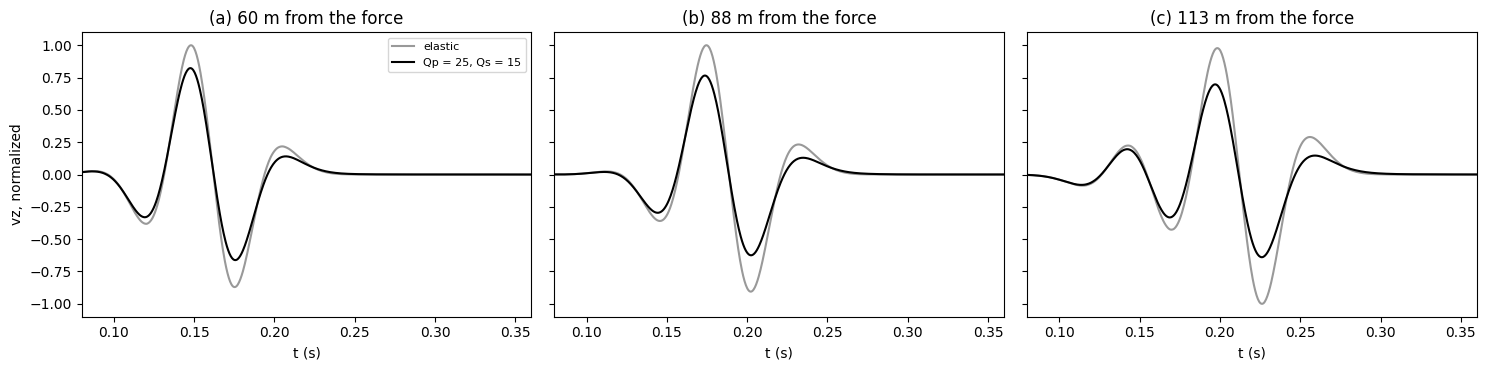

In [3]:
dist = DH * np.linalg.norm(offs, axis=1)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a_, k, lab in zip(ax, range(3), "abc"):
    s = 1.0 / np.abs(elastic[:, k]).max()
    a_.plot(t, s * elastic[:, k], color="0.6", lw=1.5, label="elastic")
    a_.plot(t, s * visco[:, k], "k", lw=1.5, label=f"Qp = {QP:.0f}, Qs = {QS:.0f}")
    a_.set_title(f"({lab}) {dist[k]:.0f} m from the force")
    a_.set_xlabel("t (s)")
    a_.set_xlim(0.08, 0.36)
ax[0].set_ylabel("vz, normalized")
ax[0].legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

The attenuated pulse is smaller and broader, and arrives at nearly the same time: `vp` and `vs`
are the phase velocities at the reference frequency, 10 Hz by default, close to the source's
12 Hz. The comparison with the visco-elastic Green's function is in
`test/sem/test_sem_visco_elastic3d.py`.

## 2. A force under a hill

`ViscoElasticVSSEM3DDeformed` follows a topography with its Hex27 mesh; the top is free and the
other five sides absorb. A vertical force 50 m under the foot of a 60 m hill, receivers along the
surface over the hill, and the same run without attenuation and with `Qp = 30`, `Qs = 20`.

In [4]:
DH2, DT2, NT2 = 10.0, 5e-4, 1600                           # 0.8 s
SHAPE2, ABCN2 = (41, 61, 101), 16                          # 400 x 600 x 1000 m
ny, nx = SHAPE2[1], SHAPE2[2]
yy, xx = np.meshgrid(np.arange(ny), np.arange(nx), indexing="ij")
topo = 6.0 - 6.0 * np.exp(-((xx - 60) ** 2 + (yy - 30) ** 2) / (2 * 12.0 ** 2))  # rows
t2 = np.arange(NT2) * DT2
a2 = (np.pi * F0 * (t2 - DELAY)) ** 2
wav2 = ((1 - 2 * a2) * np.exp(-a2)).astype(np.float32)
src2 = np.array([[25.0, 30.0, topo[30, 25] + 5.0]])
rx = np.arange(10.0, 86.0, 1.0)                           # 150 m off the C-PML
rec2 = np.stack([rx, np.full_like(rx, 30.0), topo[30, rx.astype(int)]], 1)[None]


def run2(eq, extra=()):
    p = PropSEM(eq, shape=SHAPE2, dh=DH2, dt=DT2, n_order=NO, abcn=ABCN2, topography=topo,
                free_surface=True, f_dominant=F0, dev=DEV, source_type=["vz"],
                receiver_type=["vz"])
    ms = [torch.full(SHAPE2, v, device=DEV) for v in (VP, VS, RHO) + tuple(extra)]
    with torch.no_grad():
        return p(wav2, src2, rec2, models=ms)[0, :, :, 0].cpu().numpy()


hill_el = run2(ElasticVSSEM3DDeformed)
hill_vi = run2(ViscoElasticVSSEM3DDeformed, (30.0, 20.0))

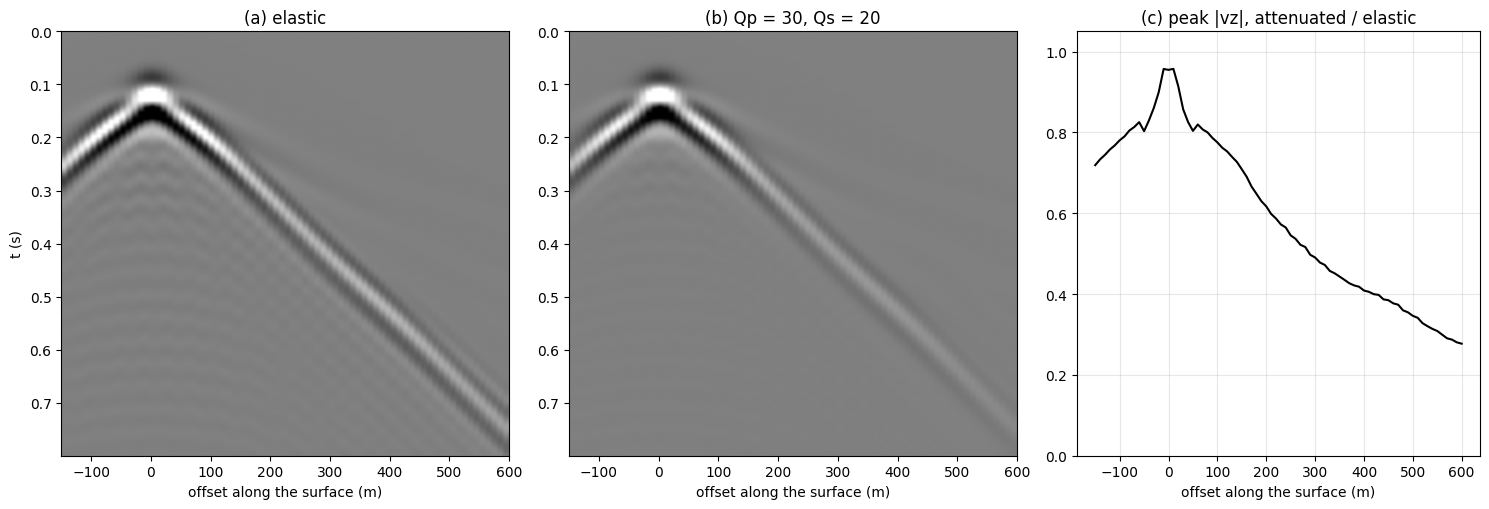

In [5]:
fig = plt.figure(figsize=(15, 5.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.9])
clip = np.percentile(np.abs(hill_el), 99.5)
off = (rx - src2[0, 0]) * DH2
for i, (data, lab) in enumerate(((hill_el, "(a) elastic"), (hill_vi, "(b) Qp = 30, Qs = 20"))):
    a_ = fig.add_subplot(gs[i])
    a_.imshow(data, aspect="auto", cmap="gray", vmin=-clip, vmax=clip,
              extent=[off[0], off[-1], t2[-1], t2[0]])
    a_.set_title(lab)
    a_.set_xlabel("offset along the surface (m)")
    if i == 0:
        a_.set_ylabel("t (s)")
a_ = fig.add_subplot(gs[2])
ratio = np.abs(hill_vi).max(0) / np.abs(hill_el).max(0)
a_.plot(off, ratio, "k")
a_.set_title("(c) peak |vz|, attenuated / elastic")
a_.set_xlabel("offset along the surface (m)")
a_.set_ylim(0.0, 1.05)
a_.grid(alpha=0.3)
fig.tight_layout()
plt.show()

The attenuated section (b) keeps the arrivals of the elastic one (a), over the hill as elsewhere,
with amplitudes that fall faster with distance (c).

---

<p><strong>Download this notebook</strong> &mdash; <a href="59_sem_visco_elastic3d.ipynb" download><code>59_sem_visco_elastic3d.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/59_sem_visco_elastic3d.ipynb">view on GitHub</a></p>